# Tutorial 1 — Gaia DR4 epoch astrometry: one single star

Gaia DR4 (2 December 2026) will publish the **epoch astrometry** of every source:
the individual along-scan positions that Gaia measured, transit by transit.
In June 2026 ESA pre-released this product for 12 sources. This tutorial uses that
public sample.

**What you will do**

1. Download the pre-release file and open it.
2. Read the structure of the table: one row per transit, ten CCDs per row.
3. Turn the table into one datum per CCD.
4. Plot the data.
5. Write the single-star model and its design matrix.
6. Fit the five astrometric parameters with one linear solve.
7. Compare the result with ESA's own fit.

**The source.** LSPM J1324+6124, `source_id` 1663617687609809280: G = 14.3 mag,
parallax ≈ 10 mas, proper motion ≈ 185 mas/yr. Both signals are large, so you can see
them in the data.

**Units and conventions**

- Sky offsets are in milliarcseconds (mas). The file gives scan angles in degrees;
  orblet uses radians.
- Time is TCB. The file counts nanoseconds from J2010.0 (JD 2455197.5 TCB). orblet
  uses days from J2010.0, or MJD.
- The DR4 reference epoch is J2017.5 TCB = MJD 57936.375
  (`orblet.constants.MJD_J2017_5_TCB`).
- $\mu_{\alpha*} = \mu_\alpha \cos\delta$.
- The data are public. When you use them, follow the
  [Gaia acknowledgement instructions](https://gea.esac.esa.int/archive/documentation/GDR3/Miscellaneous/sec_credit_and_citation_instructions/)
  and the [data licence](https://www.cosmos.esa.int/web/gaia-users/license).

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from IPython.display import Markdown

from orblet.constants import MJD_J2017_5_TCB
# The DR4 reader of these tutorials, in dr4_prerelease.py next to this notebook.
from dr4_prerelease import (PRERELEASE_URL, REF_EPOCH_DAYS_J2010, CCD_NAMES, SOURCES,
                            download_prerelease, explode_transits, matrix_markdown,
                            params_markdown)

# Where the downloaded files go. The folder is git-ignored: the data stay out of the repo.
DATA_DIR = Path("_data")
DATA_DIR.mkdir(exist_ok=True)

SOURCE_ID = 1663617687609809280   # LSPM J1324+6124

## 1. Download the data

The pre-release is one zip file (0.6 MB) on ESA's public server. No login is needed.
The zip holds one VOTable and a short readme. `download_prerelease` downloads the zip only
when it is not in `_data/` yet, and unpacks it.

In [2]:
xml_path = download_prerelease(DATA_DIR)              # one HTTPS GET, ~0.6 MB, the first time only

zip_path = DATA_DIR / PRERELEASE_URL.rsplit("/", 1)[-1]   # the file name at the end of the URL
with zipfile.ZipFile(zip_path) as zf:
    print("files in the zip:")
    for info in zf.infolist():
        print(f"  {info.filename:48s} {info.file_size:9d} bytes")

print()
print((DATA_DIR / "readme.txt").read_text())

files in the zip:
  GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml       1183282 bytes
  readme.txt                                             387 bytes

Description: Gaia DR4 epoch astrometry data for 12 sources, pre-released in June 2026.

Detailed information: see https://www.cosmos.esa.int/web/gaia/dr4-prerelease

Data license: see https://www.cosmos.esa.int/web/gaia-users/license

Acknowledgement and citation instructions: see https://gea.esac.esa.int/archive/documentation/GDR3/Miscellaneous/sec_credit_and_citation_instructions/




## 2. Open the table

The file is a VOTable (XML). `astropy.table.Table` reads it directly. The table has
one row per **field-of-view transit**: one passage of the source across Gaia's focal
plane. All 12 sources are in the same table; `source_id` tells them apart.

In [3]:
table = Table.read(xml_path, format="votable")
print(f"{len(table)} rows (transits), {len(table.colnames)} columns, "
      f"{len(np.unique(table['source_id']))} sources")

# The column inventory, from the VOTable metadata. dtype 'object' marks a column that
# holds one small array per row: one entry per CCD.
rows = ["| column | per | dtype | unit | description |", "|---|---|---|---|---|"]
for name in table.colnames:
    col = table[name]
    per = "CCD" if col.dtype == object else "transit"
    unit = "" if col.unit is None else str(col.unit)
    rows.append(f"| `{name}` | {per} | {col.dtype} | {unit} | {col.description} |")
Markdown("\n".join(rows))

1008 rows (transits), 37 columns, 12 sources


| column | per | dtype | unit | description |
|---|---|---|---|---|
| `solution_id` | transit | int64 |  | Solution Identifier |
| `source_id` | transit | int64 |  | Unique source identifier |
| `transit_id` | transit | int64 |  | Transit Identifier |
| `ra0` | transit | float64 | deg | Right ascension of reference point |
| `dec0` | transit | float64 | deg | Declination of reference point |
| `agis_source_excess_noise` | transit | float32 | mas | the unscaled AGIS Source Excess Noise |
| `obs_time_tcb` | CCD | object | ns | effective observing time as TCB |
| `obs_time_bary_corr` | transit | float32 | ns | barycentric correction to obsTimeTcb |
| `scan_pos_angle` | CCD | object | deg | Position angle of the scan |
| `zeta` | transit | float32 | deg | across-scan field angle zeta of the reference point (ra0, dec0) |
| `parallax_factor_al` | transit | float32 |  | Parallax factor AL |
| `parallax_factor_ac` | transit | float32 |  | Parallax factor AC |
| `colour_factor_al` | CCD | object |  | colour factor AL |
| `colour_factor_ac` | CCD | object |  | colour factor AC |
| `nu_eff_used_in_astrometry` | transit | float32 | 1 / um | colour (i.e. effective wavenumber) used in AGIS (and in IPD) |
| `nu_eff_error` | transit | float32 | 1 / um | standard error of nuEffUsedInAstrometry |
| `centroid_pos_al` | CCD | object | mas | Local plane coordinate (w) of image centroid AL |
| `centroid_pos_ac` | CCD | object | mas | Local plane coordinate (z) of image centroid AC |
| `calculated_pos_ac` | CCD | object | mas | Calculated Local plane coordinate (z) |
| `centroid_pos_error_al` | CCD | object | mas | standard error of centroidPosAl |
| `centroid_pos_error_ac` | CCD | object | mas | standard error of centroidPosAc |
| `used_by_agis_al` | CCD | object |  | whether the CCD transit was used in AL by AGIS-DR4 |
| `used_by_agis_ac` | CCD | object |  | whether the CCD transit was used in AC by AGIS-DR4 |
| `transit_acq_flags` | transit | int16 |  | Transit-level information on the on-board acquisition |
| `transit_proc_flags` | transit | int16 |  | Transit-level information on the processing results |
| `ccd_proc_flags` | CCD | object |  | CCD-level information on the processing results |
| `multipeak` | transit | bool |  | True if the AstroElementary is multipeak; false otherwise |
| `blended` | transit | bool |  | True if the peak for this source is also matched to another source |
| `ipd_error_al` | CCD | object | mas | standard error of IDU IPD centroid AL |
| `ipd_error_ac` | CCD | object | mas | standard error of IDU IPD centroid AC (NaN for 1d windows) |
| `g_mag` | transit | float32 | mag | G Magnitude, either from CU5 or from on-board estimate |
| `g_class` | transit | int16 |  | Window class used in SM, AF and XP |
| `gates` | CCD | object |  | Gate information for all CCDs |
| `source_dist_to_last_ci` | CCD | object | pix | source distance to last charge injection |
| `ac_rate` | transit | float32 | pix / s | AstroElementary AC rates for the transit time |
| `sub_pixel_coord` | CCD | object | pix | Subpixel coordinate AL |
| `mu` | CCD | object | pix | Ac coordinate of the image (or window centre) on a CCD |

Read the table in two groups:

- **per transit** (one number per row): `source_id`, `transit_id`, the reference point
  `ra0`, `dec0`, the parallax factor `parallax_factor_al`, the barycentric time
  correction `obs_time_bary_corr`, the source excess noise, the magnitude, and flags.
- **per CCD** (one array per row): the observing time `obs_time_tcb`, the scan angle
  `scan_pos_angle`, the along-scan position `centroid_pos_al` with its error
  `centroid_pos_error_al`, and the quality flag `used_by_agis_al`.

The next cell lists the 12 sources with their transit counts.

In [4]:
# SOURCES: a table from source_id to the name and a note from the ESA pre-release page.
rows = ["| source_id | name | group | transits | G (mag) | excess noise (mas) |",
        "|---|---|---|---:|---:|---:|"]
for sid, info in SOURCES.items():
    sel = table[table["source_id"] == sid]
    name = info["name"] if info["name"] is not None else "-"
    rows.append(f"| {sid} | {name} | {info['note']} | {len(sel)} | "
                f"{np.median(np.asarray(sel['g_mag'], dtype=float)):.1f} | "
                f"{float(sel['agis_source_excess_noise'][0]):.3f} |")
Markdown("\n".join(rows))

| source_id | name | group | transits | G (mag) | excess noise (mas) |
|---|---|---|---:|---:|---:|
| 4181040337841125632 | HD 183633 | parallax ~1 mas, G 9 | 97 | 9.0 | 0.000 |
| 3926186255616949504 | - | parallax ~1 mas, G 19 | 81 | 19.0 | 0.000 |
| 435469040545191680 | - | parallax ~1 mas, G 14 | 81 | 14.0 | 0.000 |
| 1663617687609809280 | LSPM J1324+6124 | G 14, parallax ~10 mas | 95 | 14.3 | 0.000 |
| 2309425390592896 | - | G 14, parallax ~1 mas | 75 | 14.0 | 0.000 |
| 20694084440761600 | - | G 14, parallax ~5 mas | 74 | 14.0 | 0.000 |
| 2237987199365376 | - | quasar (CRF3) | 88 | 19.8 | 0.000 |
| 60730287810150016 | - | quasar (CRF3) | 73 | 20.5 | 0.000 |
| 10973744521070720 | - | quasar (CRF3) | 62 | 19.9 | 0.619 |
| 3937211745905473024 | HD 114762 | orbit: brown-dwarf companion | 90 | 7.2 | 1.227 |
| 1457486023639239296 | Gaia-4 | orbit: planet Gaia-4 b | 115 | 11.9 | 0.119 |
| 4318465066420528000 | Gaia BH3 | orbit: dormant black hole | 77 | 11.2 | 6.583 |

## 3. One transit, ten CCDs

During a transit the source image crosses the **sky mapper** (SM) and then nine
**astrometric field** CCDs, AF1 to AF9. Each CCD gives one along-scan position. That
is why the per-CCD columns hold ten entries. The next cell prints one transit.

In [5]:
rows_src = table[table["source_id"] == SOURCE_ID]
row = rows_src[0]

t_ns = np.ma.filled(np.ma.asarray(row["obs_time_tcb"]).astype(float), np.nan)
lines = [f"**transit_id {row['transit_id']}**, reference point "
         f"ra0 = {row['ra0']:.6f} deg, dec0 = {row['dec0']:.6f} deg, "
         f"parallax_factor_al = {row['parallax_factor_al']:.4f}, "
         f"obs_time_bary_corr = {row['obs_time_bary_corr'] / 1e9:.1f} s",
         "",
         "| CCD | time - t(SM) (s) | scan_pos_angle (deg) | centroid_pos_al (mas) "
         "| centroid_pos_error_al (mas) | used_by_agis_al |",
         "|---|---:|---:|---:|---:|---|"]
for k in range(10):
    lines.append(f"| {CCD_NAMES[k]} | {(t_ns[k] - t_ns[0]) / 1e9:.2f} "
                 f"| {row['scan_pos_angle'][k]:.3f} | {row['centroid_pos_al'][k]:.3f} "
                 f"| {row['centroid_pos_error_al'][k]:.3f} | {row['used_by_agis_al'][k]} |")
Markdown("\n".join(lines))

**transit_id 49531623125694197**, reference point ra0 = 201.230513 deg, dec0 = 61.410223 deg, parallax_factor_al = -0.6236, obs_time_bary_corr = 172.5 s

| CCD | time - t(SM) (s) | scan_pos_angle (deg) | centroid_pos_al (mas) | centroid_pos_error_al (mas) | used_by_agis_al |
|---|---:|---:|---:|---:|---|
| SM | 0.00 | 132.174 | -5.117 | 0.251 | False |
| AF1 | 9.91 | 132.174 | -4.782 | 0.181 | True |
| AF2 | 14.77 | 132.174 | -5.000 | 0.167 | True |
| AF3 | 19.63 | 132.174 | -4.995 | 0.162 | True |
| AF4 | 24.49 | 132.174 | -4.982 | 0.156 | True |
| AF5 | 29.35 | 132.174 | -4.994 | 0.157 | True |
| AF6 | 34.21 | 132.174 | -5.106 | 0.154 | True |
| AF7 | 39.07 | 132.174 | -4.548 | 0.158 | True |
| AF8 | 43.93 | 132.174 | -5.023 | 0.156 | True |
| AF9 | 48.79 | 132.174 | -4.795 | 0.154 | True |

What to see in this table:

- The AF CCDs are 4.9 s apart, and the SM is 10 s before AF1. One transit lasts
  about 50 s.
- The scan angle is the same for all CCDs of the transit.
- `centroid_pos_al` is the along-scan coordinate $w$ of the image, relative to the
  reference point (`ra0`, `dec0`). The SM value has a larger error: the SM is a
  different detector with a coarser sampling.
- `used_by_agis_al` is `True` only for CCDs that the Gaia astrometric solution (AGIS)
  used. The SM is never used. Some AF CCDs are rejected as outliers.

## 4. From transits to CCD data

orblet wants flat arrays: one datum per CCD. The function `explode_transits` of
`dr4_prerelease.py` (next to this notebook; all four tutorials import it) does this.
Open the file to read the code. The steps:

1. Select the rows of one source.
2. Flatten the ten CCD slots of every row.
3. Convert the time: nanoseconds since J2010.0 → days since J2010.0, plus the
   barycentric (Rømer) correction `obs_time_bary_corr`. ESA applies this
   correction too. It is at most 6 minutes.
4. Convert the scan angle: degrees → radians.
5. Keep a CCD datum only when `used_by_agis_al` is `True` and all its values are
   finite. This removes the SM and the rejected CCDs.

Two more steps are optional or not used here: the source excess noise can be added to
the errors (`add_excess_noise=True`), and the colour fields of tutorial 4 are carried
along (they do not change which data are kept).

The output is the dictionary orblet reads: `obs_time`, `scan_angle`, `centroid_pos`,
`centroid_pos_err`, `parallax_factor_al`.

In [6]:
astro = explode_transits(table, SOURCE_ID)
n_kept = astro["obs_time"].size
print(f"{astro['n_transits']} transits -> {astro['n_ccd_total']} CCD slots -> "
      f"{n_kept} data kept ({n_kept / astro['n_ccd_total']:.0%})")
print(f"time span: {(astro['obs_time'].max() - astro['obs_time'].min()) / 365.25:.2f} yr")
print(f"median error per CCD: {np.median(astro['centroid_pos_err']):.3f} mas")
print(f"source excess noise: {astro['excess_noise_mas']:.3f} mas")

95 transits -> 950 CCD slots -> 781 data kept (82%)
time span: 5.21 yr
median error per CCD: 0.157 mas
source excess noise: 0.000 mas


## 5. Look at the data

Four views of the same data. The reading guide is below the figure.

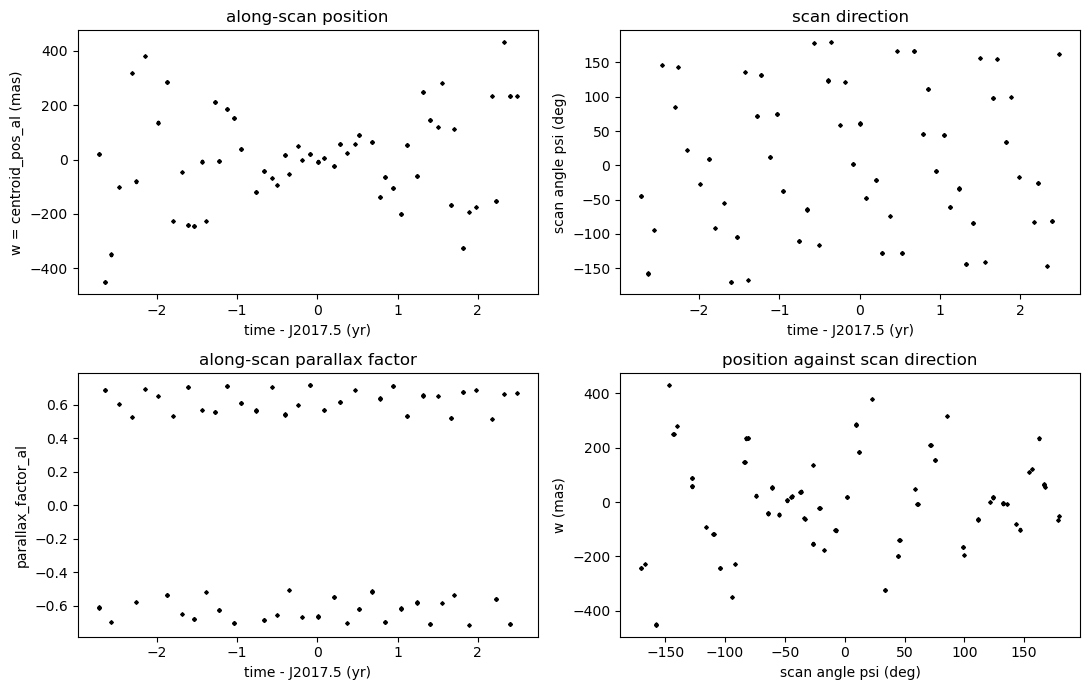

In [7]:
t_days = astro["obs_time"]
t_yr = (t_days - REF_EPOCH_DAYS_J2010) / 365.25     # years from J2017.5
psi = astro["scan_angle"]
w = astro["centroid_pos"]
sig = astro["centroid_pos_err"]
pf = astro["parallax_factor_al"]

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].errorbar(t_yr, w, yerr=sig, fmt=".", ms=3, color="k", lw=0.5)
ax[0, 0].set_xlabel("time - J2017.5 (yr)"); ax[0, 0].set_ylabel("w = centroid_pos_al (mas)")
ax[0, 0].set_title("along-scan position")

ax[0, 1].plot(t_yr, np.rad2deg(psi), ".", ms=3, color="k")
ax[0, 1].set_xlabel("time - J2017.5 (yr)"); ax[0, 1].set_ylabel("scan angle psi (deg)")
ax[0, 1].set_title("scan direction")

ax[1, 0].plot(t_yr, pf, ".", ms=3, color="k")
ax[1, 0].set_xlabel("time - J2017.5 (yr)"); ax[1, 0].set_ylabel("parallax_factor_al")
ax[1, 0].set_title("along-scan parallax factor")

ax[1, 1].plot(np.rad2deg(psi), w, ".", ms=3, color="k")
ax[1, 1].set_xlabel("scan angle psi (deg)"); ax[1, 1].set_ylabel("w (mas)")
ax[1, 1].set_title("position against scan direction")
plt.tight_layout(); plt.show()

**Reading guide**

- *Along-scan position.* $w$ is the offset from the reference point, projected on the
  scan direction. The spread grows away from J2017.5: that is the proper motion,
  185 mas/yr, seen under changing scan directions. The yearly wobble of the parallax
  is hidden inside this spread.
- *Scan direction.* Gaia scans each source a few times per year, under a small set of
  angles. The angle $\psi$ is the position angle of the scan, counted from north
  through east. Points in one cluster come from the same transit (ten CCDs).
- *Parallax factor.* The along-scan parallax factor $f_\mathrm{AL}$ is the projection
  of the parallax ellipse on the scan direction, at the time of the transit. It is
  between −1 and 1. Gaia measures the parallax best when $|f_\mathrm{AL}|$ is large.
  For this star it is always ±0.5 to ±0.7: the scanning law observes a source at
  high ecliptic latitude under two main directions.
- *Position against scan direction.* The same data, folded on $\psi$. The proper
  motion makes the large spread; the sign follows $\sin\psi$ and $\cos\psi$.

## 6. The single-star model

Gaia measures one number per CCD: the along-scan coordinate $w$. The model of a single
star has five parameters. With $\Delta t = (t - t_\mathrm{ref}) / 365.25$ in years and
$t_\mathrm{ref}$ = J2017.5:

$$
w(t, \psi) = \Delta\alpha^* \sin\psi + \Delta\delta \cos\psi
+ \mu_{\alpha*}\,\Delta t\,\sin\psi + \mu_\delta\,\Delta t\,\cos\psi
+ \varpi\, f_\mathrm{AL}
$$

| symbol | meaning | unit |
|---|---|---|
| $\Delta\alpha^*$, $\Delta\delta$ | position offset from (`ra0`, `dec0`) at $t_\mathrm{ref}$ | mas |
| $\mu_{\alpha*}$, $\mu_\delta$ | proper motion ($\mu_{\alpha*} = \mu_\alpha\cos\delta$) | mas/yr |
| $\varpi$ | parallax | mas |
| $\psi$ | scan position angle, from north through east | rad |
| $f_\mathrm{AL}$ | along-scan parallax factor, from the file | – |

Two facts make the fit easy:

1. $\sin\psi$ multiplies the east–west terms and $\cos\psi$ the north–south terms.
   Along-scan means: the observation is the sky offset projected on the unit vector
   $(\sin\psi, \cos\psi)$.
2. The model is **linear** in the five parameters. Write the $n$ observations as a
   vector $\mathbf{w}$ and the parameters as $\boldsymbol\beta$. Then

$$
\mathbf{w} = X \boldsymbol\beta + \boldsymbol\epsilon, \qquad
X = \big[\;\sin\psi,\; \cos\psi,\; \Delta t \sin\psi,\; \Delta t \cos\psi,\; f_\mathrm{AL}\;\big],
\qquad
\boldsymbol\beta = (\Delta\alpha^*, \Delta\delta, \mu_{\alpha*}, \mu_\delta, \varpi)^\top .
$$

$X$ is the **design matrix**, $n \times 5$. With the weights $W = \mathrm{diag}(1/\sigma_i^2)$
the weighted least-squares solution and its covariance are

$$
\hat{\boldsymbol\beta} = (X^\top W X)^{-1} X^\top W \mathbf{w}, \qquad
\mathrm{Cov}(\hat{\boldsymbol\beta}) = (X^\top W X)^{-1}.
$$

orblet builds $X$ with `astrometric_5param_design_matrix` and solves with
`linear_solve_ti`. The next cell prints the first rows of $X$.

In [8]:
from orblet import resolve_epochs_mjd
from orblet.solve.astrometry import astrometric_5param_design_matrix

t_mjd = resolve_epochs_mjd(astro)       # days since J2010.0 -> MJD (adds 55197.0)
X = astrometric_5param_design_matrix(t_mjd, psi, pf, epoch_ref_mjd=MJD_J2017_5_TCB)

COLUMNS = ["sin psi", "cos psi", "dt sin psi", "dt cos psi", "f_AL"]
PARAMS = ["dra* (mas)", "ddec (mas)", "pmra* (mas/yr)", "pmdec (mas/yr)", "plx (mas)"]

matrix_markdown(X, COLUMNS, n_rows=8, caption="Design matrix X of the single-star model")

**Design matrix X of the single-star model** (shape 781 x 5)

| row | sin psi | cos psi | dt sin psi | dt cos psi | f_AL |
|---|---:|---:|---:|---:|---:|
| 0 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| 1 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| 2 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| 3 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| 4 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| 5 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| 6 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| 7 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 |
| ... | ... | ... | ... | ... | ... |

Rows 0–7 are CCDs of the first transit. Columns 1 and 2 are the same for all CCDs of
a transit, because the scan angle is. Columns 3 and 4 are columns 1 and 2 times
$\Delta t$ in years; the first transit is 1.2 yr before J2017.5, so the signs flip.
Column 5 is the parallax factor of the transit.

## 7. Solve

`fit_astrometric_5param` builds this design matrix and runs the weighted
least-squares solve. It returns the parameters, their covariance, the model, the
residuals, and two quality numbers: $\chi^2$ per degree of freedom and the RMS of the
residuals.

ESA's reference values come from the package `gaiasupdate` run on the same file
(ESA tutorial notebook). ESA fits a sixth parameter (a colour term), adds the source
excess noise, and down-weights outliers. So small differences are expected.

In [9]:
from orblet.solve.astrometry import fit_astrometric_5param

sol = fit_astrometric_5param(astro, epoch_ref_mjd=MJD_J2017_5_TCB)
sigma_beta = np.sqrt(np.diag(sol.cov))

# gaiasupdate 6-parameter fit, ESA tutorial notebook (Gaia-DR4-prerelease_analyse_epoch_astrometry).
ESA = [None, None, -124.573287, -135.823929, 10.106683]

display(params_markdown(PARAMS, sol.params, sigma_beta, reference=ESA, ref_label="ESA gaiasupdate",
                        caption="Five-parameter solution of LSPM J1324+6124 at J2017.5"))
print(f"chi2 / dof = {sol.chi2_per_dof:.3f}   residual RMS = {sol.rms_mas:.4f} mas   "
      f"n = {w.size}, dof = {w.size - 5}")

**Five-parameter solution of LSPM J1324+6124 at J2017.5**

| parameter | value | sigma | ESA gaiasupdate | diff / sigma |
|---|---:|---:|---:|---:|
| dra* (mas) | 0.0005 | 0.0082 | - | - |
| ddec (mas) | -0.0013 | 0.0080 | - | - |
| pmra* (mas/yr) | -124.5727 | 0.0057 | -124.5733 | 0.10 |
| pmdec (mas/yr) | -135.8241 | 0.0055 | -135.8239 | -0.03 |
| plx (mas) | 10.1051 | 0.0091 | 10.1067 | -0.17 |

chi2 / dof = 1.082   residual RMS = 0.1703 mas   n = 781, dof = 776


In [10]:
# The correlation matrix tells which parameters the scan pattern separates well.
corr = sol.cov / np.outer(sigma_beta, sigma_beta)
short = ["dra*", "ddec", "pmra*", "pmdec", "plx"]
lines = ["| | " + " | ".join(short) + " |", "|---|" + "---:|" * 5]
for i in range(5):
    lines.append(f"| {short[i]} | " + " | ".join(f"{corr[i, j]:+.2f}" for j in range(5)) + " |")
Markdown("**Correlation matrix**\n\n" + "\n".join(lines))

**Correlation matrix**

| | dra* | ddec | pmra* | pmdec | plx |
|---|---:|---:|---:|---:|---:|
| dra* | +1.00 | +0.05 | +0.01 | +0.01 | -0.10 |
| ddec | +0.05 | +1.00 | +0.01 | +0.05 | +0.00 |
| pmra* | +0.01 | +0.01 | +1.00 | +0.12 | +0.01 |
| pmdec | +0.01 | +0.05 | +0.12 | +1.00 | -0.06 |
| plx | -0.10 | +0.00 | +0.01 | -0.06 | +1.00 |

Read the results:

- The proper motion agrees with ESA to 0.001 mas/yr and the parallax to 0.002 mas.
  ESA's extra ingredients (colour term, outlier weights) move the solution by less
  than one formal sigma.
- $\chi^2/\mathrm{dof} \approx 1.1$: the single-star model describes the data at the
  level of the quoted errors. In tutorial 2 this number tells you when a star is not
  single.
- The formal errors assume that the CCD data are independent. Within one transit they
  are not fully independent, so the formal errors are optimistic. Gaia's catalogue
  errors include further calibration terms.
- The correlations are small. Gaia's scanning law separates position, proper motion
  and parallax well when the data cover several years.

## 8. What the quality flag does

Step 5 of `explode_transits` kept only the CCDs with `used_by_agis_al = True`. The
next cell repeats the fit with all finite AF data (SM excluded) and compares.

| data set | n | chi2 / dof | RMS (mas) | plx (mas) | pmra* (mas/yr) | pmdec (mas/yr) |
|---|---:|---:|---:|---:|---:|---:|
| AGIS-used CCDs only | 781 | 1.08 | 0.170 | 10.1051 | -124.573 | -135.824 |
| all AF CCDs | 801 | 1340.31 | 7.236 | 10.3382 | -124.464 | -135.735 |

largest |residual / sigma| among the rejected CCDs: 1034


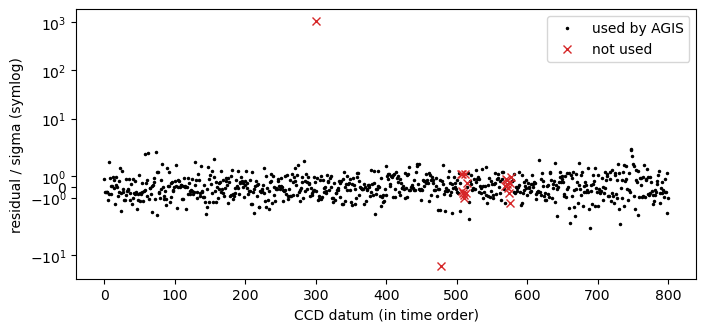

In [11]:
astro_all = explode_transits(table, SOURCE_ID, keep_only_agis=False)
not_sm = astro_all["ccd_index"] > 0
astro_all = {k: (v[not_sm] if isinstance(v, np.ndarray) else v) for k, v in astro_all.items()}
sol_all = fit_astrometric_5param(astro_all, epoch_ref_mjd=MJD_J2017_5_TCB)

lines = ["| data set | n | chi2 / dof | RMS (mas) | plx (mas) | pmra* (mas/yr) | pmdec (mas/yr) |",
         "|---|---:|---:|---:|---:|---:|---:|"]
for label, s, a in [("AGIS-used CCDs only", sol, astro), ("all AF CCDs", sol_all, astro_all)]:
    lines.append(f"| {label} | {a['obs_time'].size} | {s.chi2_per_dof:.2f} | {s.rms_mas:.3f} "
                 f"| {s.params[4]:.4f} | {s.params[2]:.3f} | {s.params[3]:.3f} |")
display(Markdown("\n".join(lines)))

# Where are the rejected CCDs? Residuals of the full set under the AGIS-only solution.
X_all = astrometric_5param_design_matrix(resolve_epochs_mjd(astro_all), astro_all["scan_angle"],
                                         astro_all["parallax_factor_al"], epoch_ref_mjd=MJD_J2017_5_TCB)
resid_all = astro_all["centroid_pos"] - X_all @ sol.params
used_all = np.isin(astro_all["transit_id"] * 10 + astro_all["ccd_index"],
                   astro["transit_id"] * 10 + astro["ccd_index"])
pull_all = resid_all / astro_all["centroid_pos_err"]
print(f"largest |residual / sigma| among the rejected CCDs: {np.max(np.abs(pull_all[~used_all])):.0f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.where(used_all, pull_all, np.nan), ".", ms=3, color="k", label="used by AGIS")
ax.plot(np.where(used_all, np.nan, pull_all), "x", ms=6, color="C3", label="not used")
ax.set_yscale("symlog", linthresh=5)          # the rejected CCDs are off by hundreds of sigma
ax.set_xlabel("CCD datum (in time order)"); ax.set_ylabel("residual / sigma (symlog)")
ax.legend(); plt.show()

Only 20 CCDs are rejected, but two of them are far off: one by 1000 sigma. Without
the flag, $\chi^2/\mathrm{dof}$ jumps to more than 1000 and the parallax moves by
25 formal sigma. Other rejected CCDs look normal: AGIS rejects on more than the
residual (for example on processing flags). Always apply the flag before a fit. The
tutorials keep the flag on from here.

## 9. Residuals, and the two signals seen one at a time

A good fit leaves residuals with no structure against time and against scan angle.
The second row of the figure removes the fitted terms one group at a time, so you see
the parallax signal and the proper-motion signal separately. The model points are
red; they are discrete because $f_\mathrm{AL}$ and $\psi$ change from transit to transit.

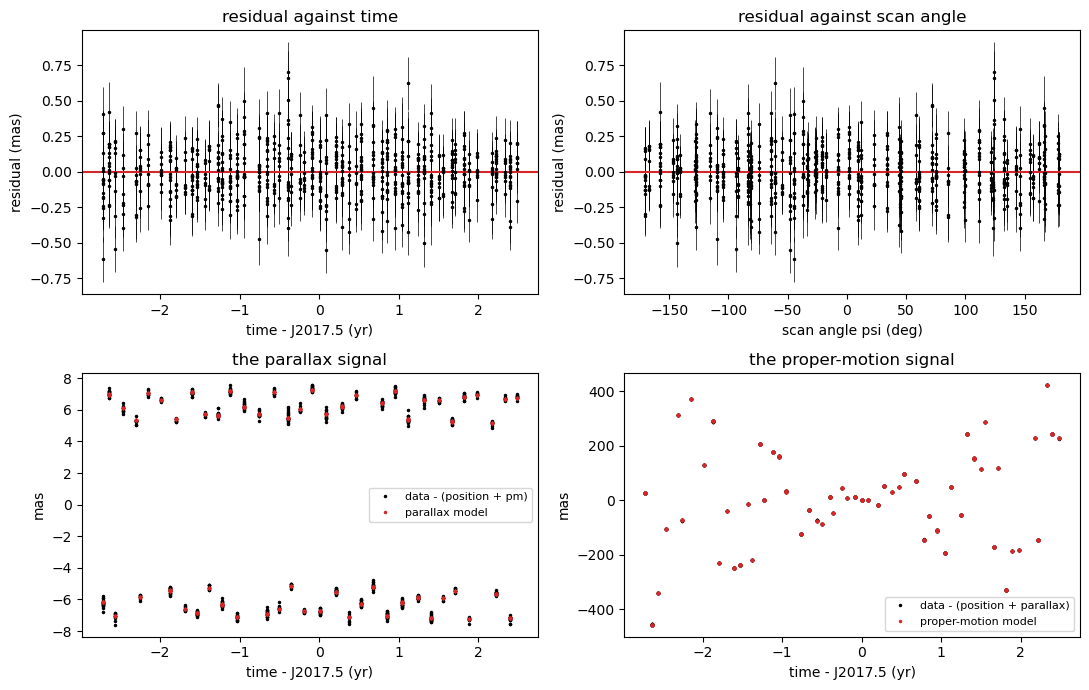

In [12]:
beta = sol.params
resid = sol.residuals
pos_pm = X[:, :4] @ beta[:4]          # position + proper-motion terms
plx_term = X[:, 4] * beta[4]          # parallax term

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].errorbar(t_yr, resid, yerr=sig, fmt=".", ms=3, color="k", lw=0.5)
ax[0, 0].axhline(0, color="C3"); ax[0, 0].set_xlabel("time - J2017.5 (yr)")
ax[0, 0].set_ylabel("residual (mas)"); ax[0, 0].set_title("residual against time")

ax[0, 1].errorbar(np.rad2deg(psi), resid, yerr=sig, fmt=".", ms=3, color="k", lw=0.5)
ax[0, 1].axhline(0, color="C3"); ax[0, 1].set_xlabel("scan angle psi (deg)")
ax[0, 1].set_ylabel("residual (mas)"); ax[0, 1].set_title("residual against scan angle")

ax[1, 0].plot(t_yr, w - pos_pm, ".", ms=3, color="k", label="data - (position + pm)")
ax[1, 0].plot(t_yr, plx_term, ".", ms=3, color="C3", label="parallax model")
ax[1, 0].set_xlabel("time - J2017.5 (yr)"); ax[1, 0].set_ylabel("mas")
ax[1, 0].set_title("the parallax signal"); ax[1, 0].legend(fontsize=8)

ax[1, 1].plot(t_yr, w - plx_term - X[:, :2] @ beta[:2], ".", ms=3, color="k", label="data - (position + parallax)")
ax[1, 1].plot(t_yr, X[:, 2:4] @ beta[2:4], ".", ms=3, color="C3", label="proper-motion model")
ax[1, 1].set_xlabel("time - J2017.5 (yr)"); ax[1, 1].set_ylabel("mas")
ax[1, 1].set_title("the proper-motion signal"); ax[1, 1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- The residuals scatter around zero, with no trend in time and no pattern in scan
  angle. The model is complete for this star.
- The parallax signal is $\varpi f_\mathrm{AL}$. For this star $f_\mathrm{AL}$ is
  ±0.6, so the signal is ±6 mas, with the sign set by the scan direction. The red
  model points sit on the black data points.
- The proper-motion signal is a straight line in time, projected on the scan
  direction, so its sign flips with $\psi$. It reaches ±480 mas at the ends of the
  data.

## 10. The absolute position

The offsets $\Delta\alpha^*$ and $\Delta\delta$ are relative to the reference point
(`ra0`, `dec0`). To get the catalogue position at J2017.5, add them back. Divide
$\Delta\alpha^*$ by $\cos\delta$ for the right ascension.

In [13]:
MAS_PER_DEG = 3.6e6
ra0, dec0 = astro["ra0_deg"], astro["dec0_deg"]
ra = ra0 + beta[0] / np.cos(np.deg2rad(dec0)) / MAS_PER_DEG
dec = dec0 + beta[1] / MAS_PER_DEG
print(f"reference point : ra0 = {ra0:.8f} deg, dec0 = {dec0:.8f} deg")
print(f"fitted offsets  : dra* = {beta[0]:+.4f} +/- {sigma_beta[0]:.4f} mas, "
      f"ddec = {beta[1]:+.4f} +/- {sigma_beta[1]:.4f} mas")
print(f"position J2017.5: ra  = {ra:.8f} deg, dec = {dec:.8f} deg (TCB, ICRS)")
print("The offsets are below 0.01 mas: the reference point already is the DR4 position.")

reference point : ra0 = 201.23051263 deg, dec0 = 61.41022305 deg
fitted offsets  : dra* = +0.0005 +/- 0.0082 mas, ddec = -0.0013 +/- 0.0080 mas
position J2017.5: ra  = 201.23051263 deg, dec = 61.41022305 deg (TCB, ICRS)
The offsets are below 0.01 mas: the reference point already is the DR4 position.


## 11. The path on the sky

Gaia measures one coordinate per CCD, along the scan. To draw the star's path on
the sky you need the model for the other coordinate. The file gives only the
along-scan parallax factor, so orblet computes the two sky components of the
parallax, $F_{\alpha*}$ and $F_\delta$, from the solar-system ephemeris with Gaia
at L2 (`per_direction_parallax_factors`). The cell checks them against the file.

Each transit mean is placed at the model position, moved by its residual along the
scan direction. The colour is time.

along-scan parallax factor, orblet vs file: rms difference 0.0012


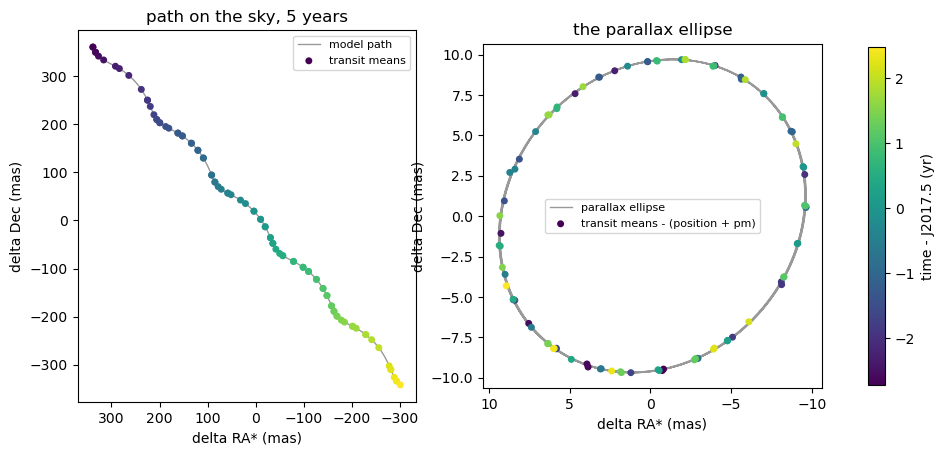

In [14]:
from orblet.parallax import per_direction_parallax_factors


def sky_model(t, beta):
    # 2-D offsets (dRA*, dDec) in mas from (ra0, dec0): position + proper motion + parallax.
    dt = (t - MJD_J2017_5_TCB) / 365.25
    F_ra, F_dec = per_direction_parallax_factors(t, astro["ra0_deg"], astro["dec0_deg"])
    return beta[0] + beta[2] * dt + beta[4] * F_ra, beta[1] + beta[3] * dt + beta[4] * F_dec


F_ra, F_dec = per_direction_parallax_factors(t_mjd, astro["ra0_deg"], astro["dec0_deg"])
f_al_orblet = F_ra * np.sin(psi) + F_dec * np.cos(psi)
print(f"along-scan parallax factor, orblet vs file: rms difference {np.sqrt(np.mean((f_al_orblet - pf) ** 2)):.4f}")

# Data on the sky: model position + residual along the scan direction, averaged per transit.
ra_m, dec_m = sky_model(t_mjd, beta)
uniq, inv = np.unique(astro["transit_id"], return_inverse=True)
n_per = np.bincount(inv)
ra_tr, dec_tr, t_tr = (np.bincount(inv, a) / n_per for a in
                       (ra_m + resid * np.sin(psi), dec_m + resid * np.cos(psi), t_yr))

t_curve = np.linspace(t_mjd.min(), t_mjd.max(), 3000)
dt_c = (t_curve - MJD_J2017_5_TCB) / 365.25
ra_c, dec_c = sky_model(t_curve, beta)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
ax[0].plot(ra_c, dec_c, color="0.6", lw=1, label="model path")
sc = ax[0].scatter(ra_tr, dec_tr, c=t_tr, cmap="viridis", s=16, zorder=3, label="transit means")
ax[0].set_title("path on the sky, 5 years")
# Parallax alone: remove the position and the proper motion from both the model and the data.
ax[1].plot(ra_c - beta[0] - beta[2] * dt_c, dec_c - beta[1] - beta[3] * dt_c, color="0.6", lw=1, label="parallax ellipse")
ax[1].scatter(ra_tr - beta[0] - beta[2] * t_tr, dec_tr - beta[1] - beta[3] * t_tr, c=t_tr, cmap="viridis", s=16, zorder=3,
              label="transit means - (position + pm)")
ax[1].set_title("the parallax ellipse")
for a in ax:
    a.set_xlabel("delta RA* (mas)"); a.set_ylabel("delta Dec (mas)"); a.invert_xaxis(); a.set_aspect("equal"); a.legend(fontsize=8)
fig.colorbar(sc, ax=ax, label="time - J2017.5 (yr)", shrink=0.8); plt.show()

Left: five years of proper motion, 185 mas/yr towards the south-west, with the
yearly parallax wiggle on top. Right: the same data with the position and the
proper motion removed. The parallax ellipse is 10 mas across; its shape follows the
ecliptic latitude of the star. Remember that only the along-scan coordinate of each
point is measured; the across-scan coordinate comes from the model.

## Summary

- The DR4 epoch astrometry table has one row per transit and ten CCD entries per
  row. The quality flag `used_by_agis_al` selects the data that Gaia used.
- The single-star model is linear in five parameters. One weighted least-squares
  solve gives the parameters and their covariance.
- The fit of LSPM J1324+6124 reproduces ESA's solution. $\chi^2/\mathrm{dof} \approx 1$
  says the model is complete.

**Exercises**

1. Set `SOURCE_ID` to `4181040337841125632` (HD 183633, G = 9) and run again. How
   does the error per CCD change with magnitude? Compare with a G = 19 source.
2. Set `SOURCE_ID` to a quasar. The parallax must be zero within its error. Is it?
3. Remove the barycentric time correction in `explode_transits`. Does any parameter
   move by more than 0.1 sigma? (Think about the size of the correction: 6 minutes
   on a 5-year baseline.)
4. Tutorial 2 fits an orbit to a source where $\chi^2/\mathrm{dof}$ is not 1.